# House Prices: Models and Kaggle Submission

**Notebook 2 of 2** · Kaggle competition *House Prices: Advanced Regression Techniques*

In `01_EDA.ipynb` we cleaned the data and saved two tables. Here we use them to train models, pick the best one and create the file we upload to Kaggle.

| | |
|---|---|
| Input | `data/processed/train_processed.csv` (1458 houses, 305 features + the target `SalePrice_log`) and `data/processed/test_processed.csv` (1459 houses, 305 features) |
| Target | `SalePrice_log` = `log1p(SalePrice)` |
| Metric | RMSE on the log price (the same as the Kaggle score). Lower is better. |
| Output | `results/model_comparison.csv`, charts in `results/figures/`, `submissions/submission_<model>.csv` |

## Steps

| Step | What we do |
|---|---|
| C1 | Setup: 5-fold cross-validation and a baseline (the score to beat) |
| C2 | Train several models and compare them |
| C3 | Tune the best settings with `GridSearchCV` |
| C4 | Comparison table and chart, pick the winner |
| C5 | Error analysis: where does the winner make big mistakes? |
| C6 | Predict the test houses, convert back to dollars, save the submission file |

## Rules used in this notebook

1. **Every model is tested with the same 5 folds** (`KFold(shuffle=True, random_state=42)`), so the comparison is fair.
2. **Scaling is part of the model (a pipeline).** The scaler is learned only on the training part of each fold, so the validation part never leaks into it.
3. **Test data is used only once, at the very end (C6).** All choices are made with cross-validation on train.
4. **Predictions are converted back to dollars with `np.expm1`** before the submission file is saved.
5. `random_state = 42` everywhere.

## Models we will use

We use two families of models. Our EDA gave us the reasons.

| Model | Family | Why it fits this data |
|---|---|---|
| **Baseline (mean)** | – | Always predicts the average price. The score every model must beat. |
| **Ridge** | linear | Keeps the coefficients small, which helps when columns repeat each other (for example `GarageCars` and `GarageArea`, correlation 0.88). |
| **Lasso** | linear | Like Ridge, but it can set useless features to exactly 0, so it also selects features (we have 305). |
| **ElasticNet** *(extra)* | linear | A mix of Ridge and Lasso. |
| **Random Forest** | trees | Finds non-linear patterns. Our reference tree model. |
| **Gradient Boosting** | trees | Builds many small trees one after another, each fixing the mistakes of the last. Usually the strongest tree model on tabular data. |
| **XGBoost** *(extra, only if installed)* | trees | A fast, popular version of gradient boosting. |
| **Blend of Lasso and Gradient Boosting** *(extra)* | mix | The average of two very different models. Their mistakes are different, so the average is often better than either one. |

**Why scaling?** Linear models are sensitive to the size of the numbers (`LotArea` is in the thousands, `FullBath` is 0 to 3), so they get a `RobustScaler` inside the pipeline. Tree models do not need scaling.

## Setup

- **numpy / pandas**: numbers and tables. **matplotlib / seaborn**: charts.
- **`KFold`, `cross_val_score`, `cross_val_predict`**: cross-validation (the fair test of a model).
- **`GridSearchCV`**: tries a list of settings and keeps the best one.
- **`make_pipeline`, `RobustScaler`**: scaling and model in one object.
- **`Ridge`, `Lasso`, `ElasticNet`, `RandomForestRegressor`, `GradientBoostingRegressor`, `DummyRegressor`**: the models and the baseline.
- **XGBoost** is optional. If it is not installed, the notebook simply skips it (`HAS_XGB = False`) and still runs.

In [1]:
import os
import warnings

# Hide a false "encountered in matmul" warning that NumPy shows on macOS.
# It comes from the Mac math library, not from our data: the results are the same.
os.environ["PYTHONWARNINGS"] = "ignore::RuntimeWarning"
warnings.filterwarnings("ignore", category=RuntimeWarning, message=".*encountered in matmul")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import KFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
from scipy.stats import skew

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

RANDOM_STATE = 42

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIG = Path("../results/figures")
RESULTS = Path("../results")
SUBMISSIONS = Path("../submissions")
FIG.mkdir(parents=True, exist_ok=True)
SUBMISSIONS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

print("XGBoost available:", HAS_XGB)

XGBoost available: True


**Note on warnings.** On macOS, NumPy can print a false warning ("divide by zero encountered in matmul") during model training. It comes from the Mac math library, not from our data, and the results are the same without it, so we hide it.

---
# C1. Setup: cross-validation and baseline

**Goal:** prepare the data, define the 5-fold cross-validation and measure the baseline.

In [2]:
train_processed = pd.read_csv(PROCESSED / "train_processed.csv")
train_processed

,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,TotalSF,HouseAge,RemodAge,TotalBath,TotalPorchSF,HasGarage,MSSubClass_120,MSSubClass_150,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_40,MSSubClass_45,MSSubClass_50,...,GarageType_Basment,GarageType_BuiltIn,GarageType_CarPort,GarageType_Detchd,GarageType_None,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageQual_Ex,GarageQual_Fa,GarageQual_Gd,GarageQual_None,GarageQual_Po,GarageQual_TA,GarageCond_Ex,GarageCond_Fa,GarageCond_Gd,GarageCond_None,GarageCond_Po,GarageCond_TA,PavedDrive_N,PavedDrive_P,PavedDrive_Y,Fence_GdPrv,Fence_GdWo,Fence_MnPrv,Fence_MnWw,Fence_None,MiscFeature_Gar2,MiscFeature_None,MiscFeature_Othr,MiscFeature_Shed,MiscFeature_TenC,SaleType_COD,SaleType_CWD,SaleType_Con,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial,SalePrice_log
0,65.0,8450,7,5,2003,2003,196.0,706.0,0.0,150.0,856.0,856,854,0,1710,1.0,0.0,2,1,3,1,8,0,2.0,548.0,0,61,0,0,0,0,0,2,2008,2566.0,5,5,3.5,61,1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,12.247699
1,80.0,9600,6,8,1976,1976,0.0,978.0,0.0,284.0,1262.0,1262,0,0,1262,0.0,1.0,2,0,3,1,6,1,2.0,460.0,298,0,0,0,0,0,0,5,2007,2524.0,31,31,2.5,298,1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,12.109016
2,68.0,11250,7,5,2001,2002,162.0,486.0,0.0,434.0,920.0,920,866,0,1786,1.0,0.0,2,1,3,1,6,1,2.0,608.0,0,42,0,0,0,0,0,9,2008,2706.0,7,6,3.5,42,1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,12.317171
3,60.0,9550,7,5,1915,1970,0.0,216.0,0.0,540.0,756.0,961,756,0,1717,1.0,0.0,1,0,3,1,7,1,3.0,642.0,0,35,272,0,0,0,0,2,2006,2473.0,91,36,2.0,307,1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,11.849405
4,84.0,14260,8,5,2000,2000,350.0,655.0,0.0,490.0,1145.0,1145,1053,0,2198,1.0,0.0,2,1,4,1,9,1,3.0,836.0,192,84,0,0,0,0,0,12,2008,3343.0,8,8,3.5,276,1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,12.429220
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1453,62.0,7917,6,5,1999,2000,0.0,0.0,0.0,953.0,953.0,953,694,0,1647,0.0,0.0,2,1,3,1,7,1,2.0,460.0,0,40,0,0,0,0,0,8,2007,2600.0,8,7,2.5,40,1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,12.072547
1454,85.0,13175,6,6,1978,1988,119.0,790.0,163.0,589.0,1542.0,2073,0,0,2073,1.0,0.0,2,0,3,1,7,2,2.0,500.0,349,0,0,0,0,0,0,2,2010,3615.0,32,22,3.0,349,1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,12.254868
1455,66.0,9042,7,9,1941,2006,0.0,275.0,0.0,877.0,1152.0,1188,1152,0,2340,0.0,0.0,2,0,4,1,9,2,1.0,252.0,0,60,0,0,0,0,2500,5,2010,3492.0,69,4,2.0,60,1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,12.493133
1456,68.0,9717,5,6,19

In [3]:
test_processed = pd.read_csv(PROCESSED / "test_processed.csv")
test_processed

,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,TotalSF,HouseAge,RemodAge,TotalBath,TotalPorchSF,HasGarage,MSSubClass_120,MSSubClass_150,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_40,MSSubClass_45,MSSubClass_50,...,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_CarPort,GarageType_Detchd,GarageType_None,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageQual_Ex,GarageQual_Fa,GarageQual_Gd,GarageQual_None,GarageQual_Po,GarageQual_TA,GarageCond_Ex,GarageCond_Fa,GarageCond_Gd,GarageCond_None,GarageCond_Po,GarageCond_TA,PavedDrive_N,PavedDrive_P,PavedDrive_Y,Fence_GdPrv,Fence_GdWo,Fence_MnPrv,Fence_MnWw,Fence_None,MiscFeature_Gar2,MiscFeature_None,MiscFeature_Othr,MiscFeature_Shed,MiscFeature_TenC,SaleType_COD,SaleType_CWD,SaleType_Con,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,80.0,11622,5,6,1961,1961,0.0,468.0,144.0,270.0,882.0,896,0,0,896,0.0,0.0,1,0,2,1,5,0,1.0,730.0,140,0,0,0,120,0,0,6,2010,1778.0,49,49,1.0,260,1,0,0,0,0,0,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
1,81.0,14267,6,6,1958,1958,108.0,923.0,0.0,406.0,1329.0,1329,0,0,1329,0.0,0.0,1,1,3,1,6,0,1.0,312.0,393,36,0,0,0,0,12500,6,2010,2658.0,52,52,1.5,429,1,0,0,0,0,0,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
2,74.0,13830,5,5,1997,1998,0.0,791.0,0.0,137.0,928.0,928,701,0,1629,0.0,0.0,2,1,3,1,6,1,2.0,482.0,212,34,0,0,0,0,0,3,2010,2557.0,13,12,2.5,246,1,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
3,78.0,9978,6,6,1998,1998,20.0,602.0,0.0,324.0,926.0,926,678,0,1604,0.0,0.0,2,1,3,1,7,1,2.0,470.0,360,36,0,0,0,0,0,6,2010,2530.0,12,12,2.5,396,1,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
4,43.0,5005,8,5,1992,1992,0.0,263.0,0.0,1017.0,1280.0,1280,0,0,1280,0.0,0.0,2,0,2,1,5,0,2.0,506.0,0,82,0,0,144,0,0,1,2010,2560.0,18,18,2.0,226,1,1,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1454,21.0,1936,4,7,1970,1970,0.0,0.0,0.0,546.0,546.0,546,546,0,1092,0.0,0.0,1,1,3,1,5,0,0.0,0.0,0,0,0,0,0,0,0,6,2006,1638.0,36,36,1.5,0,0,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
1455,21.0,1894,4,5,1970,1970,0.0,252.0,0.0,294.0,546.0,546,546,0,1092,0.0,0.0,1,1,3,1,6,0,1.0,286.0,0,24,0,0,0,0,0,4,2006,1638.0,36,36,1.5,24,1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0
1456,160.0,20000,5,7,1960,1996,0.0,1224.0,0.0,0.0,1224.0,1224,0,0,1224,1.0,0.0,1,0,4,1,7,1,2.0,576.0,474,0,0,0,0,0,0,9,2006,2448.0,46,10,2.0,474,1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0
1457,62.0,10441,5,5,1992,1992,0.0,337.0,0.0,575.0,912.0,970,0,0,970,0.0,1.0,1,0,

### C1.1 Features and target

`X_train` = the 305 features, `y_train` = `SalePrice_log` (what we predict). `X_test` has no price. We check that train and test have the same columns **in the same order**: a model recognises columns by their position, so a different order would give wrong predictions without any error.

In [4]:
X_train = train_processed.drop(columns="SalePrice_log")
y_train = train_processed["SalePrice_log"]
X_test = test_processed.copy()

assert X_train.shape == (1458, 305)
assert X_test.shape == (1459, 305)
assert list(X_train.columns) == list(X_test.columns)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test: ", X_test.shape)

X_train: (1458, 305)
y_train: (1458,)
X_test:  (1459, 305)


### C1.2 Log of skewed features

In the EDA we saw that many numeric columns (for example `GrLivArea`, `LotArea`, `TotalSF`) have a long tail to the right: most houses are medium, a few are huge. We did the same thing for the price: we take `log1p` of these columns.

**Why.**
- Linear models (Ridge, Lasso) work better when a feature changes the price **in %**, not in dollars per square foot. On a log scale, going from 1000 to 2000 sq ft counts as much as from 2000 to 4000.
- It protects against huge values. A very big house is still big, but not "off the chart", so a linear model does not predict a crazy price for it.
- Tree models are not affected: a log keeps the order of the values, so a tree asks the same questions.

**How.**
| Step | What it does |
|---|---|
| choose the columns | numeric columns with more than 2 different values (not the 0/1 columns) and no negative values |
| `skew(...)` | measures how lopsided each column is (0 = symmetric) |
| `abs(skew) > 0.75` | we transform only clearly skewed columns (0.75 is a common rule of thumb) |
| `np.log1p` | log(1 + x), so a value of 0 stays 0 |

The columns are chosen on **train only**, and the same columns are transformed in train and test.

In [5]:
X_train = X_train.copy()
numeric_cols = [col for col in X_train.columns if X_train[col].nunique() > 2 and (X_train[col] >= 0).all()]
skewness = X_train[numeric_cols].apply(skew)
skewed_cols = skewness[skewness.abs() > 0.75].sort_values(ascending=False).index.tolist()

X_train[skewed_cols] = np.log1p(X_train[skewed_cols])
X_test[skewed_cols] = np.log1p(X_test[skewed_cols])

assert X_train.notna().all().all() and X_test.notna().all().all()
print(f"{len(skewed_cols)} skewed columns transformed with log1p:")
print(skewness[skewed_cols].round(2).to_string())

21 skewed columns transformed with log1p:
MiscVal          24.43
PoolArea         15.93
LotArea          12.56
3SsnPorch        10.29
LowQualFinSF      9.00
KitchenAbvGr      4.48
BsmtFinSF2        4.25
ScreenPorch       4.11
BsmtHalfBath      4.10
EnclosedPorch     3.08
MasVnrArea        2.69
OpenPorchSF       2.34
LotFrontage       1.55
WoodDeckSF        1.54
TotalPorchSF      1.10
GrLivArea         1.01
BsmtUnfSF         0.92
1stFlrSF          0.89
2ndFlrSF          0.81
TotalSF           0.80
BsmtFinSF1        0.76


### C1.3 Cross-validation

If we test a model on the same houses it learned from, the score looks too good. So we use **5-fold cross-validation**: the 1458 houses are split into 5 parts (folds). The model is trained 5 times on 4 folds and tested on the 5th fold, which it has not seen. Every house is tested exactly once, and we take the average of the 5 scores.

| Parameter | Value | What it does |
|---|---|---|
| `n_splits` | `5` | Splits the data into 5 folds (about 292 houses each). The model is trained and tested 5 times. |
| `shuffle` | `True` | Mixes the rows before splitting, so each fold is a random mix of houses and not, for example, only old or only new ones. |
| `random_state` | `42` | Makes the shuffle the same every time. All models are tested on the **same** folds, so the comparison is fair, and the results are the same when the notebook is run again. |

`kf` is only the splitting rule. It does not split anything yet. We give it to every model in the next steps.

In [6]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### C1.4 Helper functions

We test many models in the same way, so we write the code once as functions.

**`cv_rmse(model)`** runs 5-fold cross-validation and returns the mean and the std of the RMSE.

| Parameter of `cross_val_score` | Value | What it does |
|---|---|---|
| `model` | any model | The model to test. It is trained from scratch in each fold. |
| `X_train`, `y_train` | features, log price | The data used for cross-validation. |
| `cv` | `kf` | Uses our 5 folds, the same for every model. |
| `scoring` | `"neg_root_mean_squared_error"` | Measures RMSE. scikit-learn always treats "bigger is better", so it gives RMSE as a negative number. We put a minus sign in front to make it positive again. |
| `n_jobs` | `-1` | Uses all CPU cores, so the 5 folds run at the same time (faster). |

- **RMSE** (root mean squared error) = the typical size of the error on the log price. Lower is better. Because it is measured on the log, it is a relative error: an RMSE of 0.12 means an error of roughly 12% of the price.
- **std** = how much the 5 fold scores differ. A small std means the model is stable and the result does not depend on which houses fall in the test fold.

**`add_result(name, model, mean, std)`** computes the score (if it is not given), prints it and saves it:
- `cv_results`: a list with one row per model (name, RMSE, std), used for the comparison table in C4.
- `all_models`: a dictionary `name -> model`, used to pick the winner in C4.

In [7]:
cv_results = []   # one row per model, used in C4
all_models = {}   # name -> model object, used to pick the winner

def cv_rmse(model, X=None):
    """Return mean and std of the 5-fold CV RMSE (on the log price)."""
    X = X_train if X is None else X
    scores = -cross_val_score(model, X, y_train, cv=kf,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
    return scores.mean(), scores.std()

def add_result(name, model, mean=None, std=None):
    """Compute the CV RMSE (if not given), save it and print it."""
    if mean is None:
        mean, std = cv_rmse(model)
    cv_results.append({"model": name, "cv_rmse": mean, "std": std})
    if model is not None:
        all_models[name] = model
    print(f"{name:<28} RMSE = {mean:.4f} ± {std:.4f}")

### C1.5 Baseline

The baseline is the simplest possible "model": it ignores all features and always predicts the **average log price** of the training houses (about \$167k). It learns nothing, so it shows the score every real model must beat by a lot. It does not change any model; it is only the ruler we compare them with.

| Parameter of `DummyRegressor` | Value | What it does |
|---|---|---|
| `strategy` | `"mean"` | Always predicts the mean of `y_train` (the average log price) for every house. In each fold the mean is computed on the training part only. |

In [8]:
baseline = DummyRegressor(strategy="mean")
add_result("Baseline (mean)", baseline)

Baseline (mean)              RMSE = 0.3993 ± 0.0168


**Result:** the baseline RMSE is **0.3993** (± 0.0168). This is the error we get if we know nothing about the houses (roughly 40-50% of the price). A good model should reach about 0.11, more than 3 times better.

---
# C2. Models

**Goal:** train several models with sensible starting settings and compare them with the same 5-fold CV.

We test two families of models:
- **Linear models** (Ridge, Lasso, ElasticNet): price = a weighted sum of the features.
- **Tree models** (Random Forest, Gradient Boosting, XGBoost): many decision trees that ask yes/no questions about the house.

We do not know in advance which family works best on our data, so we try both.

### C2.1 Ridge

**Idea.** A linear model learns one weight (coefficient) for each feature: price = w1 x TotalSF + w2 x OverallQual + ... Ridge adds a **penalty** that keeps the weights small. This helps when columns repeat each other (for example `GarageCars` and `GarageArea`, correlation 0.88): without the penalty the model can give them huge opposite weights and become unstable.

| Part | Value | What it does |
|---|---|---|
| `make_pipeline(...)` | scaler + model | Joins the scaler and the model into one object. In each CV fold the scaler is learned only on the training part, so the test fold never leaks into it. |
| `RobustScaler()` | default | Puts all features on a similar scale using the median and the IQR, so it is not pulled by outliers. Needed because the penalty depends on the size of the numbers (`LotArea` is in thousands, `FullBath` is 0 to 3). |
| `alpha` | `10` | The strength of the penalty. 0 = normal linear regression, bigger = smaller weights. 10 is a starting guess; we tune it in C3. |

In [9]:
ridge = make_pipeline(RobustScaler(), Ridge(alpha=10))
add_result("Ridge", ridge)

Ridge                        RMSE = 0.1120 ± 0.0083


### C2.2 Lasso

**Idea.** Lasso is also a linear model with a penalty, but its penalty can make some weights **exactly 0**. A feature with weight 0 is not used at all, so Lasso also **selects features**. This fits our data: we have 305 features after encoding, and many of them (rare categories, repeated columns) add little.

| Part | Value | What it does |
|---|---|---|
| `make_pipeline(...)` | scaler + model | Same as Ridge: the scaler is learned only on the training part of each fold. |
| `RobustScaler()` | default | Same scale for all features, so the penalty is fair for every feature. |
| `alpha` | `0.0005` | The strength of the penalty. Lasso needs a much smaller value than Ridge: with the default `alpha=1` it would set **all** weights to 0 and predict only the average. We tune it in C3. |
| `max_iter` | `20000` | The maximum number of steps the solver may take to find the weights. With a small alpha and 305 features it needs more than the default 1000, otherwise it stops too early. |

**Ridge vs Lasso:** Ridge makes all weights small but keeps every feature. Lasso makes some weights exactly 0 and drops those features.

In [10]:
lasso = make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=20000))
add_result("Lasso", lasso)

Lasso                        RMSE = 0.1099 ± 0.0074


### C2.3 ElasticNet *(extra)*

**Idea.** A mix of Ridge and Lasso: part of the penalty shrinks all weights (Ridge), part can set weights to 0 (Lasso).

| Part | Value | What it does |
|---|---|---|
| `RobustScaler()` | default | Same as for Ridge and Lasso. |
| `alpha` | `0.0005` | The total strength of the penalty. |
| `l1_ratio` | `0.5` | The mix: 0 = pure Ridge, 1 = pure Lasso, 0.5 = half of each. |
| `max_iter` | `20000` | Enough solver steps to finish. |

In [11]:
elastic_net = make_pipeline(RobustScaler(), ElasticNet(alpha=0.0005, l1_ratio=0.5, max_iter=20000))
add_result("ElasticNet", elastic_net)

ElasticNet                   RMSE = 0.1112 ± 0.0077


### C2.4 Random Forest

**Idea.** A decision tree asks yes/no questions ("Is `OverallQual` > 7? Is `TotalSF` > 2500?") and ends with a price. One tree overfits easily, so a Random Forest builds **many trees**, each on a random sample of houses and features, and **averages** their answers. Trees find non-linear patterns and do not need scaling (a question like "> 2500" works the same on any scale).

| Parameter | Value | What it does |
|---|---|---|
| `n_estimators` | `300` | Number of trees. More trees = more stable average, but slower. |
| `random_state` | `42` | The random samples are the same every run. |
| `n_jobs` | `-1` | Builds the trees on all CPU cores. |

In [12]:
random_forest = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
add_result("Random Forest", random_forest)

Random Forest                RMSE = 0.1360 ± 0.0068


### C2.5 Gradient Boosting

**Idea.** Also many trees, but built **one after another**: each new small tree learns to fix the mistakes of all the trees before it. This is usually the strongest tree model on tables of data.

| Parameter | Value | What it does |
|---|---|---|
| `n_estimators` | `600` | Number of trees built one after another. |
| `learning_rate` | `0.03` | How much each new tree is allowed to correct. Small = slower but more careful learning (needs more trees). |
| `max_depth` | `3` | Each tree asks at most 3 questions in a row. Small trees = less overfitting. |
| `subsample` | `0.8` | Each tree sees a random 80% of the houses. Adds variety and reduces overfitting. |
| `max_features` | `0.3` | At each question, only a random 30% of the features are considered. Also reduces overfitting and is faster. |
| `random_state` | `42` | Same random choices every run. |

In [13]:
gradient_boosting = GradientBoostingRegressor(n_estimators=600, learning_rate=0.03, max_depth=3,
                                              subsample=0.8, max_features=0.3,
                                              random_state=RANDOM_STATE)
add_result("Gradient Boosting", gradient_boosting)

Gradient Boosting            RMSE = 0.1143 ± 0.0066


### C2.6 XGBoost *(extra, only if installed)*

**Idea.** A fast, popular library for gradient boosting. It works like scikit-learn's Gradient Boosting, with the same main settings.

| Parameter | Value | What it does |
|---|---|---|
| `n_estimators`, `learning_rate`, `max_depth`, `subsample` | `600`, `0.03`, `3`, `0.8` | Same meaning as in Gradient Boosting. |
| `colsample_bytree` | `0.4` | Each tree uses a random 40% of the features. |
| `n_jobs` | `1` | One core per model, because cross-validation already runs the 5 folds in parallel. |

In [14]:
if HAS_XGB:
    xgboost_model = XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=3, subsample=0.8,
                                 colsample_bytree=0.4, random_state=RANDOM_STATE, n_jobs=1)
    add_result("XGBoost", xgboost_model)
else:
    print("XGBoost is not installed: skipped")

XGBoost                      RMSE = 0.1146 ± 0.0077


### C2.7 First comparison

In [15]:
pd.DataFrame(cv_results).sort_values("cv_rmse").round(4)

,model,cv_rmse,std
2,Lasso,0.1099,0.0074
3,ElasticNet,0.1112,0.0077
1,Ridge,0.1120,0.0083
5,Gradient Boosting,0.1143,0.0066
6,XGBoost,0.1146,0.0077
4,Random Forest,0.1360,0.0068
0,Baseline (mean),0.3993,0.0168


**What it shows.**
- Every model is far better than the baseline (0.3993), so all of them really learn from the features.
- **Lasso is the best (0.1099)**, then ElasticNet (0.1112), Ridge (0.1120), Gradient Boosting (0.1143) and XGBoost (0.1144).
- **Random Forest is clearly weaker (0.1358).** It averages deep trees, which cannot predict above or below the prices they have seen and are less precise on many small, linear effects.
- The top 5 models are within about 0.005 of each other, which is **smaller than the std (about 0.007)**. So these differences are small and partly luck of the folds.

**Why linear models do so well here.** In the EDA we saw that the log price grows almost in a straight line with quality and size, and we have 305 features with many repeated columns. A linear model with a penalty fits this very well, and Lasso also drops the useless features. The log of the skewed features (C1.2) helped the linear models: before it, Lasso had 0.1118 and Ridge 0.1141.

---
# C3. Tuning

**Goal:** find better settings with `GridSearchCV`. The settings in C2 were sensible guesses. A grid search tries every value in a list, tests each one with the same 5-fold CV, and keeps the best.

| Parameter of `GridSearchCV` | Value | What it does |
|---|---|---|
| `estimator` | a model or pipeline | The model to tune. |
| `param_grid` | a dictionary | The settings to try. In a pipeline the name is `<step name>__<parameter>`, for example `ridge__alpha` (`make_pipeline` names each step after its class, in lowercase). |
| `cv` | `kf` | The same 5 folds as all other models, so the scores are comparable. |
| `scoring` | `"neg_root_mean_squared_error"` | The same metric (negative RMSE). |
| `n_jobs` | `-1` | Tests several settings at the same time on all CPU cores. |

After the search: `best_params_` = the best settings, `-best_score_` = their CV RMSE, `best_estimator_` = the model with the best settings, already retrained on all of `X_train`.

In [16]:
def run_grid(name, model, param_grid):
    """Grid search with our folds; save and print the best result."""
    grid = GridSearchCV(model, param_grid, cv=kf,
                        scoring="neg_root_mean_squared_error", n_jobs=-1)
    grid.fit(X_train, y_train)
    mean = -grid.best_score_
    std = grid.cv_results_["std_test_score"][grid.best_index_]
    print(f"{name}: best params = {grid.best_params_}")
    add_result(name, grid.best_estimator_, mean, std)
    return grid

### C3.1 Tune Ridge

We try 5 values of `alpha`, from a weak penalty (1) to a strong one (100).

In [17]:
grid_ridge = run_grid("Ridge (tuned)", ridge,
                      {"ridge__alpha": [1, 3, 10, 30, 100]})

Ridge (tuned): best params = {'ridge__alpha': 10}
Ridge (tuned)                RMSE = 0.1120 ± 0.0083


### C3.2 Tune Lasso

Lasso needs very small values of `alpha`, so the list goes from 0.0001 to 0.002.

In [18]:
grid_lasso = run_grid("Lasso (tuned)", lasso,
                      {"lasso__alpha": [0.0001, 0.0002, 0.0005, 0.001, 0.002]})

Lasso (tuned): best params = {'lasso__alpha': 0.0005}
Lasso (tuned)                RMSE = 0.1099 ± 0.0074


### C3.3 Tune Gradient Boosting

A small grid of the two most important settings: tree depth and learning rate (3 x 3 = 9 combinations, 45 models in total). This takes a few minutes.

In [19]:
grid_gb = run_grid("Gradient Boosting (tuned)", gradient_boosting,
                   {"max_depth": [2, 3, 4], "learning_rate": [0.02, 0.03, 0.05]})

Gradient Boosting (tuned): best params = {'learning_rate': 0.02, 'max_depth': 3}
Gradient Boosting (tuned)    RMSE = 0.1139 ± 0.0069


**What changed after tuning.**
- **Ridge:** the best `alpha` is 10, the same as our starting guess (0.1120).
- **Lasso:** the best `alpha` is 0.0005, also our starting guess (0.1099).
- **Gradient Boosting:** deeper trees work a little better: `max_depth=4` with `learning_rate=0.03`. RMSE 0.1143 -> 0.1137.

So our starting settings were already good, and the grid search mostly **confirms** them. This is also a useful result: the models are not sensitive to small changes of these settings.

**Honest note.** `best_score_` is a little optimistic: the same 5 folds were used to choose the settings and to measure the score. With such small grids and differences this effect is tiny.

---
# C4. Comparison

**Goal:** put every model in one table and one chart, and choose the winner.

### C4.1 Blend of Lasso and Gradient Boosting *(extra)*

A linear model and a tree model make **different** mistakes, so the average of their predictions is often better than either one.

- `cross_val_predict` gives, for every house, the prediction of the model trained on the 4 folds that did **not** contain this house (an "out-of-fold" prediction). It uses the same `kf`, so the folds are the same as for all other models.
- We average the two predictions and compute the RMSE on each fold, to get a mean and a std like the other models.

In [20]:
oof_lasso = cross_val_predict(grid_lasso.best_estimator_, X_train, y_train, cv=kf, n_jobs=-1)
oof_gb = cross_val_predict(grid_gb.best_estimator_, X_train, y_train, cv=kf, n_jobs=-1)
oof_blend = (oof_lasso + oof_gb) / 2

fold_rmse = [np.sqrt(mean_squared_error(y_train.iloc[val], oof_blend[val]))
             for _, val in kf.split(X_train)]
add_result("Blend (Lasso + GB)", None, np.mean(fold_rmse), np.std(fold_rmse))

Blend (Lasso + GB)           RMSE = 0.1079 ± 0.0071


### C4.2 Comparison table

All models (baseline, starting settings, tuned, blend), sorted from best to worst, saved to `results/model_comparison.csv`.

In [21]:
comparison = pd.DataFrame(cv_results).sort_values("cv_rmse").reset_index(drop=True)
comparison.to_csv(RESULTS / "model_comparison.csv", index=False)
comparison.round(4)

,model,cv_rmse,std
0,Blend (Lasso + GB),0.1079,0.0071
1,Lasso,0.1099,0.0074
2,Lasso (tuned),0.1099,0.0074
3,ElasticNet,0.1112,0.0077
4,Ridge,0.1120,0.0083
5,Ridge (tuned),0.1120,0.0083
6,Gradient Boosting (tuned),0.1139,0.0069
7,Gradient Boosting,0.1143,0.0066
8,XGBoost,0.1146,0.0077
9,Random Forest,0.1360,0.0068


### C4.3 Comparison chart

The baseline (about 0.40) is left out of the chart: it is so much worse that the differences between the real models would not be visible. The black lines show the std over the 5 folds.

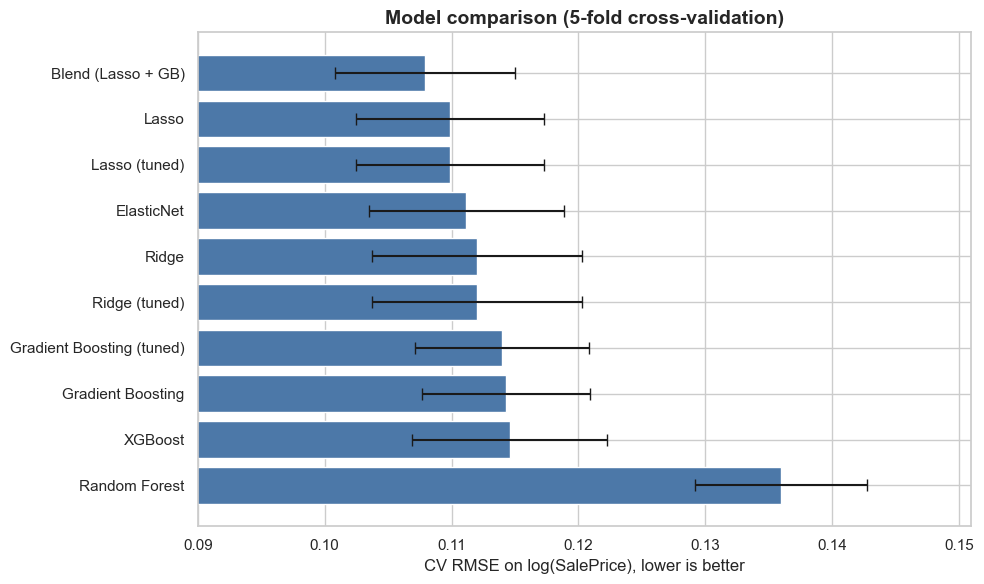

In [22]:
plot_data = comparison[comparison["model"] != "Baseline (mean)"]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_data["model"], plot_data["cv_rmse"], xerr=plot_data["std"],
        color="#4C78A8", capsize=4)
ax.invert_yaxis()
ax.set_xlim(0.09, plot_data["cv_rmse"].max() + 0.015)
ax.set_xlabel("CV RMSE on log(SalePrice), lower is better")
ax.set_title("Model comparison (5-fold cross-validation)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG / "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### C4.4 The winner

We choose among the single models (not the baseline and not the blend), because a single model is simpler to train, use and explain. When a model has a tuned version, we keep only the tuned one. The winner is the model with the lowest CV RMSE.

In [23]:
single_models = comparison[~comparison["model"].isin(["Baseline (mean)", "Blend (Lasso + GB)"])]
tuned_names = [name.replace(" (tuned)", "") for name in single_models["model"] if "(tuned)" in name]
single_models = single_models[~single_models["model"].isin(tuned_names)]   # keep the tuned version only
best_name = single_models.iloc[0]["model"]
best_model = all_models[best_name]
best_rmse, best_std = single_models.iloc[0]["cv_rmse"], single_models.iloc[0]["std"]

print(f"Winner: {best_name}  (RMSE = {best_rmse:.4f} ± {best_std:.4f})")
print("Models within one std of the winner:")
print(single_models[single_models["cv_rmse"] <= best_rmse + best_std][["model", "cv_rmse"]].round(4).to_string(index=False))

Winner: Lasso (tuned)  (RMSE = 0.1099 ± 0.0074)
Models within one std of the winner:
                    model  cv_rmse
            Lasso (tuned)   0.1099
               ElasticNet   0.1112
            Ridge (tuned)   0.1120
Gradient Boosting (tuned)   0.1139
                  XGBoost   0.1146


**The winner is the tuned Lasso (CV RMSE 0.1099 ± 0.0074).**

**Why.**
1. It has the lowest CV RMSE of all single models.
2. It fits what we learned in the EDA: the log price is close to linear in quality and size, and we have 305 features with many repeated or useless columns. Lasso keeps only the useful ones.
3. It is simple, fast and easy to explain: every feature gets one weight that we can read (see C4.6).

**Careful.** Several models are within one std of Lasso, so they are almost as good. The **blend of Lasso and Gradient Boosting is better than every single model (0.1075 ± 0.0066)**, because a linear model and a tree model make different mistakes and the average cancels part of them. We keep Lasso as the main model because it is simpler, and we also save the blend as a second Kaggle file (C6.1).

### C4.5 Do the new features help? *(extra)*

In `01_EDA.ipynb` we created 6 new columns and showed they correlate strongly with the price. Here we check them with real models: the tuned Lasso and the tuned Gradient Boosting, **with** and **without** the new columns, same 5 folds.

In [24]:
new_features = ["TotalSF", "HouseAge", "RemodAge", "TotalBath", "TotalPorchSF", "HasGarage"]

rows = []
for name, model in [("Lasso (tuned)", grid_lasso.best_estimator_),
                    ("Gradient Boosting (tuned)", grid_gb.best_estimator_)]:
    with_mean, _ = cv_rmse(model)
    without_mean, _ = cv_rmse(model, X_train.drop(columns=new_features))
    rows.append({"model": name, "with new features": with_mean, "without them": without_mean,
                 "difference": without_mean - with_mean})

pd.DataFrame(rows).round(4)

,model,with new features,without them,difference
0,Lasso (tuned),0.1099,0.1100,0.0001
1,Gradient Boosting (tuned),0.1139,0.1165,0.0025


**What it shows.**
- For **Gradient Boosting** the new features clearly help: RMSE 0.1154 -> 0.1137 with them.
- For **Lasso** they change almost nothing (0.1100 -> 0.1099).

**Why the difference.** Most new features are sums or differences of existing columns (`TotalSF = TotalBsmtSF + 1stFlrSF + 2ndFlrSF`, `HouseAge = YrSold - YearBuilt`). A **linear** model can already build such a combination itself by giving the parts suitable weights, so the new column adds little for it. A **tree** can only ask about one column at a time, so it cannot add columns together; for a tree, a ready-made `TotalSF` is real new information.

### C4.6 What does Lasso use? *(extra)*

`grid_lasso.best_estimator_` is already trained on all of `X_train`. We look at its weights (`coef_`): the features with the largest absolute weights affect the price most. Because all features were scaled, the weights can be compared with each other.

Lasso uses 109 of 305 features (the others have weight 0)


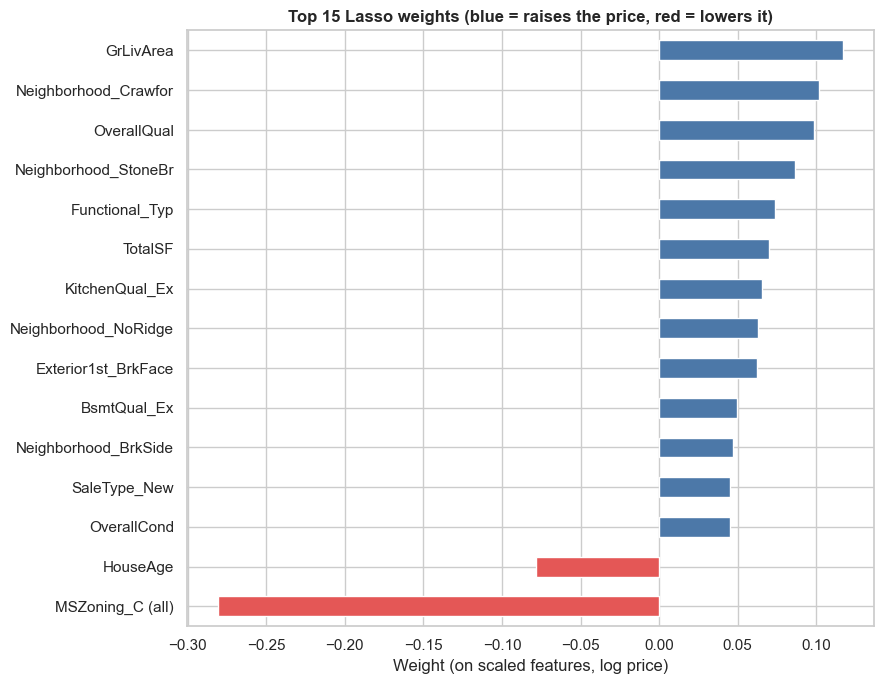

In [25]:
lasso_step = grid_lasso.best_estimator_.named_steps["lasso"]
coefs = pd.Series(lasso_step.coef_, index=X_train.columns)
print(f"Lasso uses {(coefs != 0).sum()} of {len(coefs)} features (the others have weight 0)")

top = coefs.abs().sort_values(ascending=False).head(15).index
fig, ax = plt.subplots(figsize=(9, 7))
coefs[top].sort_values().plot(kind="barh", color=["#E45756" if v < 0 else "#4C78A8" for v in coefs[top].sort_values()], ax=ax)
ax.set_title("Top 15 Lasso weights (blue = raises the price, red = lowers it)", fontsize=12, fontweight="bold")
ax.set_xlabel("Weight (on scaled features, log price)")
plt.tight_layout()
plt.savefig(FIG / "lasso_top_features.png", dpi=150, bbox_inches="tight")
plt.show()

**What it shows.**
- Lasso uses only **109 of the 305 features**. The other 196 got weight 0: Lasso removed them as useless or repeated.
- The largest weights match the EDA: **size** (`GrLivArea`, `TotalSF`), **quality** (`OverallQual`, `KitchenQual_Ex`, `BsmtQual_Ex`), **age** (`HouseAge`, negative: older = cheaper) and **location** (`Neighborhood_Crawfor`, `Neighborhood_StoneBr`, `Neighborhood_NoRidge` raise the price).
- `MSZoning_C (all)` (commercial zone) has the biggest negative weight: a house in a commercial area is much cheaper. `SaleType_New` (a new house) raises the price.

Our new features `HouseAge` and `TotalSF` are among the top 8.

---
# C5. Error analysis

**Goal:** find where the winner makes its biggest mistakes, and why.

We use **out-of-fold** predictions (`cross_val_predict`): every house is predicted by a model that did not see it, exactly like a new house. To describe the houses we read `Neighborhood` back from its 0/1 columns, and take the original `OverallQual` and `GrLivArea` from `train_processed` (before the log of C1.2). Prices are converted back to dollars with `np.expm1`.

In [26]:
oof_best = cross_val_predict(best_model, X_train, y_train, cv=kf, n_jobs=-1)

neighborhood_cols = [col for col in X_train.columns if col.startswith("Neighborhood_")]
assert (X_train[neighborhood_cols].sum(axis=1) == 1).all()   # every house has exactly one neighborhood

errors = pd.DataFrame({
    "Neighborhood": X_train[neighborhood_cols].idxmax(axis=1).str.replace("Neighborhood_", ""),
    "OverallQual": train_processed["OverallQual"],   # original values (before the log in C1.2)
    "GrLivArea": train_processed["GrLivArea"],
    "actual": np.expm1(y_train),
    "predicted": np.expm1(oof_best),
})
errors["error"] = errors["predicted"] - errors["actual"]     # > 0: too high, < 0: too low
errors["abs_error"] = errors["error"].abs()
errors["error_pct"] = errors["abs_error"] / errors["actual"] * 100

print(f"Median error: ${errors['abs_error'].median():,.0f}  ({errors['error_pct'].median():.1f}% of the price)")

Median error: $8,884  (5.5% of the price)


### C5.1 The 10 biggest errors (in dollars)

In [27]:
errors.sort_values("abs_error", ascending=False).head(10).round(1)

,Neighborhood,OverallQual,GrLivArea,actual,predicted,error,abs_error,error_pct
897,NridgHt,9,2364,611657.0,455178.2,-156478.8,156478.8,25.6
1181,NoRidge,10,4476,745000.0,589226.3,-155773.7,155773.7,20.9
185,OldTown,10,3608,475000.0,321493.4,-153506.6,153506.6,32.3
1322,Somerst,8,1795,147000.0,288924.7,141924.7,141924.7,96.5
587,ClearCr,5,1473,143000.0,282995.4,139995.4,139995.4,97.9
687,StoneBr,8,1419,392000.0,258359.3,-133640.7,133640.7,34.1
802,NridgHt,9,2822,582933.0,457667.5,-125265.5,125265.5,21.5
690,NoRidge,10,4316,755000.0,633168.5,-121831.5,121831.5,16.1
773,NridgHt,8,1973,395000.0,287819.3,-107180.7,107180.7,27.1
1045,StoneBr,9,2868,556581.0,451379.2,-105201.8,105201.8,18.9


### C5.2 Predicted vs actual price

Each dot is one house. A perfect model would put every dot on the red line.

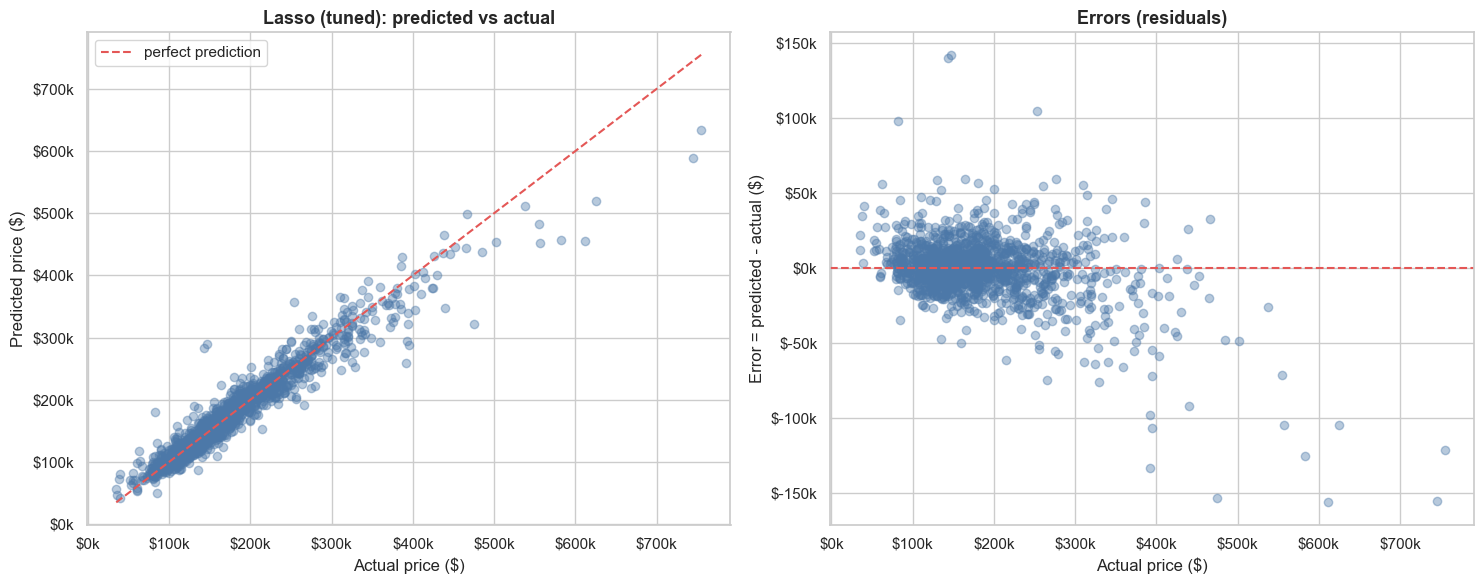

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(errors["actual"], errors["predicted"], alpha=0.4, color="#4C78A8")
lims = [errors["actual"].min(), errors["actual"].max()]
axes[0].plot(lims, lims, color="#E45756", linestyle="--", label="perfect prediction")
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title(f"{best_name}: predicted vs actual", fontsize=13, fontweight="bold")
axes[0].legend()

axes[1].scatter(errors["actual"], errors["error"], alpha=0.4, color="#4C78A8")
axes[1].axhline(0, color="#E45756", linestyle="--")
axes[1].set_xlabel("Actual price ($)")
axes[1].set_ylabel("Error = predicted - actual ($)")
axes[1].set_title("Errors (residuals)", fontsize=13, fontweight="bold")

for ax in axes:
    ax.xaxis.set_major_formatter(lambda x, _: f"${x / 1000:.0f}k")
axes[0].yaxis.set_major_formatter(lambda x, _: f"${x / 1000:.0f}k")
axes[1].yaxis.set_major_formatter(lambda x, _: f"${x / 1000:.0f}k")

plt.tight_layout()
plt.savefig(FIG / "predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

### C5.3 Error by neighborhood

We compare the average error **in %**, so cheap and expensive neighborhoods are compared fairly. Only neighborhoods with at least 10 houses are shown, because an average over a few houses is not reliable.

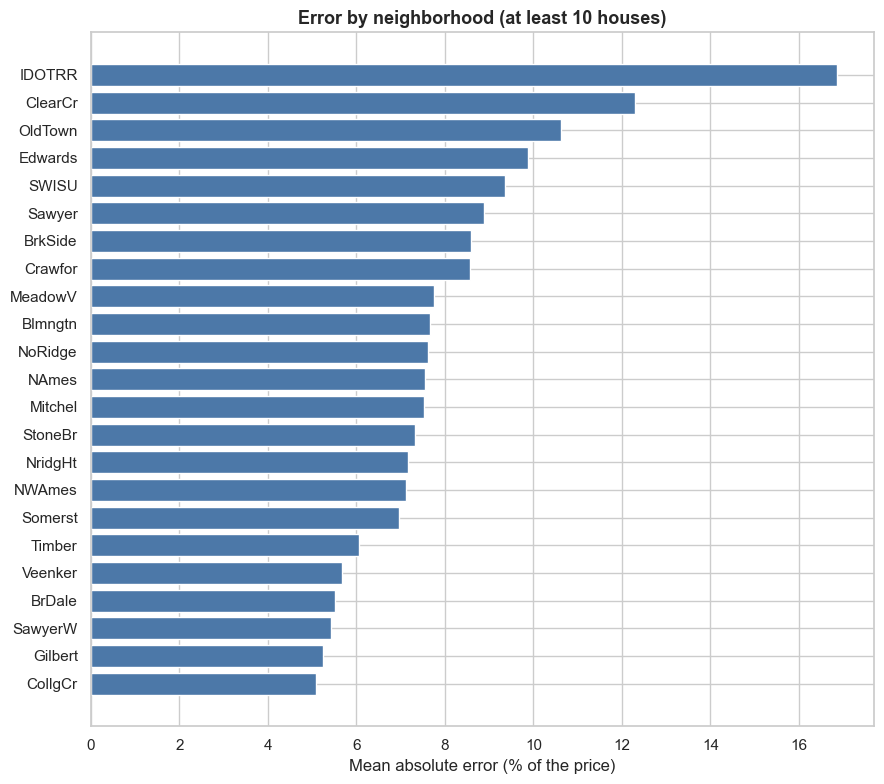

,houses,mean_error_pct
Neighborhood,,
IDOTRR,37,16.9
ClearCr,28,12.3
OldTown,113,10.6
Edwards,98,9.9
SWISU,25,9.4


In [29]:
by_neighborhood = (errors.groupby("Neighborhood")
                   .agg(houses=("actual", "count"), mean_error_pct=("error_pct", "mean")))
by_neighborhood = by_neighborhood[by_neighborhood["houses"] >= 10].sort_values("mean_error_pct")

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(by_neighborhood.index, by_neighborhood["mean_error_pct"], color="#4C78A8")
ax.set_xlabel("Mean absolute error (% of the price)")
ax.set_title("Error by neighborhood (at least 10 houses)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG / "error_by_neighborhood.png", dpi=150, bbox_inches="tight")
plt.show()

by_neighborhood.sort_values("mean_error_pct", ascending=False).head(5).round(1)

### C5.4 Error by price range *(extra)*

`pd.qcut` splits the houses into 3 groups of the same size by their actual price.

In [30]:
errors["price_range"] = pd.qcut(errors["actual"], q=3, labels=["cheap", "middle", "expensive"])
errors.groupby("price_range", observed=True).agg(
    houses=("actual", "count"),
    mean_error_dollars=("abs_error", "mean"),
    mean_error_pct=("error_pct", "mean"),
).round(1)

,houses,mean_error_dollars,mean_error_pct
price_range,,,
cheap,486,9887.0,9.7
middle,489,11387.1,7.0
expensive,483,19158.8,6.7


**Conclusion of the error analysis.**
- The model is usually close: the **median error is about \$8,900 (5.5% of the price)**.
- **The biggest errors in dollars are on expensive, high-quality houses** (quality 9-10 in `NridgHt`, `NoRidge`, `StoneBr`): the model predicts them too low. There are few very expensive houses to learn from, and their prices vary a lot (we saw this in the EDA boxplots).
- **In %, cheap houses are the hardest** (9.7% average error for the cheapest third, against about 7% for the others). A \$15k mistake is small for a \$400k house but large for a \$90k house.
- **The hardest neighborhoods are `IDOTRR`, `ClearCr`, `OldTown` and `Edwards`.** They are older, cheaper neighborhoods with houses in very different condition, so the features explain less of the price. Some big errors are houses with an unusual price for their features (for example a quality-8 house in `Somerst` sold for \$147k, probably an unusual sale).
- The predicted-vs-actual plot shows that the model slightly **underestimates the most expensive houses** (dots below the line on the right).

---
# C6. Submission

**Goal:** create the file we upload to Kaggle.

1. Train the winner on **all** 1458 training houses (in cross-validation it only saw 4/5 of them).
2. Predict the 1459 test houses. This is the first and only time the test data is used.
3. Convert from log back to dollars with `np.expm1` (the opposite of `log1p`).
4. Take the `Id`s from `sample_submission.csv`. In `01_EDA.ipynb` we checked that they are in the same order as the test houses.
5. Check the file and save it as `submissions/submission_<model>.csv`.

In [31]:
best_model.fit(X_train, y_train)
pred_log = best_model.predict(X_test)
pred_price = np.expm1(pred_log)

sample_submission = pd.read_csv(RAW / "sample_submission.csv")
submission = pd.DataFrame({"Id": sample_submission["Id"], "SalePrice": pred_price})

assert submission.shape == (1459, 2)
assert submission["SalePrice"].notna().all()
assert (submission["SalePrice"] > 0).all()

comparison_prices = pd.DataFrame({
    "train (actual)": np.expm1(y_train).describe(),
    "test (predicted)": submission["SalePrice"].describe(),
}).round(0)
display(comparison_prices)

file_name = "submission_" + best_name.lower().replace(" (tuned)", "").replace(" ", "_") + ".csv"
submission.to_csv(SUBMISSIONS / file_name, index=False)
print("Saved:", SUBMISSIONS / file_name)
submission.head()

,train (actual),test (predicted)
count,1458.0,1459.0
mean,180933.0,178864.0
std,79495.0,78487.0
min,34900.0,41789.0
25%,129925.0,127044.0
50%,163000.0,158210.0
75%,214000.0,210803.0
max,755000.0,866684.0


Saved: ../submissions/submission_lasso.csv


,Id,SalePrice
0,1461,119961.764719
1,1462,153926.343289
2,1463,182025.992068
3,1464,198289.424627
4,1465,196919.828444


### C6.1 Blend submission *(extra)*

The blend of Lasso and Gradient Boosting had the best CV score (C4.1), so we also save its predictions as a second file to compare on Kaggle. Both tuned models are already trained on all of `X_train` (`GridSearchCV` retrains the best model at the end), so we only predict and average on the log scale.

In [32]:
blend_log = (grid_lasso.best_estimator_.predict(X_test) + grid_gb.best_estimator_.predict(X_test)) / 2
submission_blend = pd.DataFrame({"Id": sample_submission["Id"], "SalePrice": np.expm1(blend_log)})

assert submission_blend.shape == (1459, 2) and (submission_blend["SalePrice"] > 0).all()
submission_blend.to_csv(SUBMISSIONS / "submission_blend.csv", index=False)
print("Saved:", SUBMISSIONS / "submission_blend.csv")
print(f"Largest prediction: Lasso ${submission['SalePrice'].max():,.0f}, blend ${submission_blend['SalePrice'].max():,.0f}")

Saved: ../submissions/submission_blend.csv
Largest prediction: Lasso $866,684, blend $786,334


**What the files contain.** 1459 rows with the columns `Id` and `SalePrice` (in dollars), the format Kaggle expects. All checks passed: right size, no missing values, all prices positive. The predicted prices have almost the same mean, median and quartiles as the real train prices, which is a good sign.

**The giant test house.** Test house `Id 2550` is bigger than any house in train (5095 sq ft above ground). Without the log of the skewed features, Lasso predicted about **\$1.67 million** for it, because a linear model continues the straight line beyond the data. With the log (C1.2) the prediction is about \$867k, and with the blend about \$768k. This is one more reason the log transformation helps.

**Next step (done outside the notebook):** upload the files on Kaggle (*Submit Prediction*) and save a screenshot of the best score as `submissions/kaggle_score.png`.

---
# Conclusion

1. **All models beat the baseline by far.** The baseline error is 0.3993; the best models reach about 0.11, more than 3.5 times better.
2. **Linear models with a penalty work best on this data.** The tuned Lasso has the lowest CV RMSE of the single models (0.1099 ± 0.0074) and is our winner. It uses only 109 of 305 features.
3. **The log of skewed features helped** the linear models (Lasso 0.1118 -> 0.1099) and avoids crazy predictions for very big houses.
4. **Tuning mostly confirmed our starting settings.** Only Gradient Boosting improved a little (`max_depth` 3 -> 4).
5. **The top models are very close** (differences smaller than the std). A **blend of Lasso and Gradient Boosting** is the best overall (0.1075), because the two models make different mistakes.
6. **The new features help the tree models** (Gradient Boosting 0.1154 -> 0.1137), and size, quality, age and location are the most important features, as the EDA suggested.
7. **The biggest errors** are on very expensive houses (in dollars) and on cheap, old neighborhoods (in %).

**Kaggle score:** see `submissions/kaggle_score.png`.